# 01. Подготовка данных

Вариант 05. Одна строка исходной выгрузки соответствует одному объявлению об аренде.
Целевая переменная – месячная арендная плата `rent_rub` в рублях.

## Пути проекта

Исходные файлы лежат в `data/raw/`. Корень проекта определяем из рабочего каталога ядра, чтобы запуск из `notebooks/` тоже находил пакет `modules`.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

if not (PROJECT_ROOT / "modules").is_dir():
    raise RuntimeError("Запустите ноутбук из корня проекта или папки notebooks/.")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"


## Загрузка и проверка формата CSV

Как в первой лабораторной и практикуме 2, сначала читаем пять строк через `pd.read_csv`. Проверяем кодировку, разделитель полей и десятичный знак по названиям районов, площади и заголовкам.

In [2]:
import pandas as pd

RAW_CSV_PATH = RAW_DATA_DIR / "rent_v05.csv"
CSV_ENCODING = "utf-8"
CSV_SEPARATOR = ","
CSV_DECIMAL = "."

sample = pd.read_csv(
    RAW_CSV_PATH,
    encoding=CSV_ENCODING,
    sep=CSV_SEPARATOR,
    decimal=CSV_DECIMAL,
    nrows=5,
)

assert pd.api.types.is_numeric_dtype(sample["total_area"]), "Площадь не прочиталась как число."

print(f"Кодировка – {CSV_ENCODING.upper()}")
print(f"Разделитель полей – {CSV_SEPARATOR!r}, десятичный знак – {CSV_DECIMAL!r}")
print(f"Пример категории – {sample.loc[0, 'district']}")
print(f"Пример дробного числа – {sample.loc[0, 'total_area']}")


Кодировка – UTF-8
Разделитель полей – ',', десятичный знак – '.'
Пример категории – Кировский
Пример дробного числа – 65.6


### Чтение всей выгрузки

Читаем значения как текст и сохраняем пустые поля, чтобы при записи сырого теста сохранить исходное представление значений. Названия и порядок столбцов совпадают с таблицей в описании варианта 05.

In [3]:
raw_df = pd.read_csv(
    RAW_CSV_PATH,
    encoding=CSV_ENCODING,
    sep=CSV_SEPARATOR,
    dtype=str,
    keep_default_na=False,
)

print("Размер выгрузки –", raw_df.shape)
print("Столбцы –", ", ".join(raw_df.columns))


Размер выгрузки – (12360, 26)
Столбцы – listing_id, publication_date, district, house_type, year_built, floors_total, floor, elevator, rooms, total_area, living_area, kitchen_area, ceiling_height, renovation, furniture, appliances, balcony, parking, metro_distance_m, distance_to_center_km, pets_allowed, seller_type, description_length, photos_count, max_tenants, rent_rub


## Удаление дублей и пустой цели

До разбиения удаляем строки, которые совпадают по всем столбцам, и строки с пустой ценой аренды. Так одна и та же строка не попадёт в разные выборки, а у каждой записи будет фактическая цена для обучения или проверки.

In [4]:
TARGET = "rent_rub"

unique_df = raw_df.drop_duplicates()
split_df = unique_df.loc[unique_df[TARGET].str.strip().ne("")]

print(f"Удалено точных дублей – {len(raw_df) - len(unique_df)}")
print(f"Удалено строк с пустым rent_rub – {len(unique_df) - len(split_df)}")
print(f"Строк для разбиения – {len(split_df)}")


Удалено точных дублей – 180
Удалено строк с пустым rent_rub – 30
Строк для разбиения – 12150


## Разбиение на train, validation и test

Как в практикуме 5, в тест откладываем 2 430 из 12 150 строк после удаления дублей и пустых цен (20 %). На валидацию берём 1 944 из оставшихся 9 720 строк (20 %). В обоих вызовах используем один `random_state`, чтобы при повторном запуске получались те же выборки.

Сырой тест сохраняем в `data/interim/rent_v05_test.csv` до приведения типов и обработки признаков. Выбранные строки сохраняют формат выгрузки заказчика, включая запись чисел и дат, пустые поля и порядок столбцов. При прогнозе сохранённый пайплайн преобразует значения в памяти. Для дальнейшего разведочного анализа и расчёта параметров предобработки используем только train, как в лекции 5.1 об утечке данных.

In [5]:
from sklearn.model_selection import train_test_split

from modules import RANDOM_STATE

TEST_FRACTION = 0.20
VALIDATION_FRACTION = 0.20

development_df, test_df = train_test_split(
    split_df, test_size=TEST_FRACTION, random_state=RANDOM_STATE
)
train_df, validation_df = train_test_split(
    development_df, test_size=VALIDATION_FRACTION, random_state=RANDOM_STATE
)

assert train_df.index.intersection(validation_df.index).empty
assert train_df.index.intersection(test_df.index).empty
assert validation_df.index.intersection(test_df.index).empty
assert len(train_df) + len(validation_df) + len(test_df) == len(split_df)

test_path = PROJECT_ROOT / "data" / "interim" / "rent_v05_test.csv"
test_path.parent.mkdir(parents=True, exist_ok=True)
test_df.sort_index().to_csv(
    test_path, encoding=CSV_ENCODING, sep=CSV_SEPARATOR, index=False, lineterminator="\n"
)

print(f"Строк в train – {len(train_df)}")
print(f"Строк в validation – {len(validation_df)}")
print(f"Строк в test – {len(test_df)}")
print("Выборки не пересекаются.")
print(f"Сырой тест сохранён в {test_path.relative_to(PROJECT_ROOT)}.")


Строк в train – 7776
Строк в validation – 1944
Строк в test – 2430
Выборки не пересекаются.
Сырой тест сохранён в data/interim/rent_v05_test.csv.


## Первичный аудит train

### Пустые поля

Как в практикуме 2, считаем количество и долю пустых полей по столбцам. При чтении CSV пустые поля сохранились как строки `""`, поэтому проверяем их через `.eq("")`. В таблицу выводим только столбцы с пустыми полями и сортируем по их количеству.

In [6]:
empty_counts = train_df.eq("").sum()

empty_summary = pd.DataFrame({
    "Пустых полей": empty_counts,
    f"Доля от всех строк train (n={len(train_df)}), %": (empty_counts / len(train_df) * 100).round(2),
})

empty_summary.loc[empty_counts.gt(0)].sort_values("Пустых полей", ascending=False)


,Пустых полей,"Доля от всех строк train (n=7776), %"
renovation,1105,14.21
kitchen_area,641,8.24
living_area,492,6.33
ceiling_height,374,4.81
balcony,318,4.09
year_built,235,3.02
parking,231,2.97
furniture,208,2.67
max_tenants,180,2.31
description_length,162,2.08


Больше всего пустых полей в описании ремонта – 1 105 из 7 776 объявлений (14,21 %). Для площади кухни проверим, связаны ли пропуски с планировкой квартиры.

In [7]:
pd.crosstab(
    train_df["rooms"], train_df["kitchen_area"].eq(""),
    rownames=["Комнаты"], colnames=["Площадь кухни"],
).rename(columns={False: "указана", True: "пусто"})

Площадь кухни,указана,пусто
Комнаты,,
1,2721,0
2,2506,0
3,1458,0
4,400,0
5,50,0
студия,0,641


В train 641 студия. У каждой из них поле площади кухни пустое, а у остальных квартир оно заполнено. Это согласуется с планировкой без отдельной кухни. При подготовке признаков стоит сохранить признак студии: заполнение общей медианой приписало бы ей площадь кухни обычной квартиры.

### Проверка полей по описанию варианта

Работаем с копией train. Переводим измерения и счётчики в числа, дату публикации – в дату со временем. Поле `rooms` содержит и числовые записи, и категорию «студия», поэтому пока оставляем его текстовым.

In [8]:
audit = train_df.replace("", pd.NA).copy()
numeric_cols = [
    "year_built", "floors_total", "floor", "total_area", "living_area",
    "kitchen_area", "ceiling_height", "balcony", "metro_distance_m",
    "distance_to_center_km", "description_length", "photos_count", "max_tenants",
    "elevator", "appliances", "pets_allowed", TARGET,
]
audit[numeric_cols] = audit[numeric_cols].apply(pd.to_numeric, errors="raise")
dates = pd.to_datetime(audit["publication_date"], format="%d.%m.%Y %H:%M", errors="raise")
print("Период публикаций –", dates.min().date(), "–", dates.max().date())
print("Разных непустых записей района –", audit["district"].nunique())
print("После удаления крайних пробелов и приведения к нижнему регистру –",
      audit["district"].str.strip().str.lower().nunique())
district_examples = audit.loc[audit["district"].str.contains("оветский", na=False), "district"]
print("Примеры написания одного района –", district_examples.unique().tolist())

Период публикаций – 2026-09-01 – 2026-10-31
Разных непустых записей района – 60
После удаления крайних пробелов и приведения к нижнему регистру – 35
Примеры написания одного района – ['советский', 'Советский р-н', 'Советский', 'Cоветский', ' Советский']


Даты охватывают сентябрь и октябрь 2026 года, как указано в описании. В `district` встречаются варианты регистра, пробелы, суффикс «р-н» и латинская C в «Cоветский». Простая нормализация регистра и пробелов уменьшает число разных записей с 60 до 35. Перед кодированием категорий нужно объединить подтверждённые варианты одного названия.

### Распределение месячной аренды

count      7776
mean      25739
std       15397
min        8000
25%       16000
50%       21500
75%       30500
max      233500


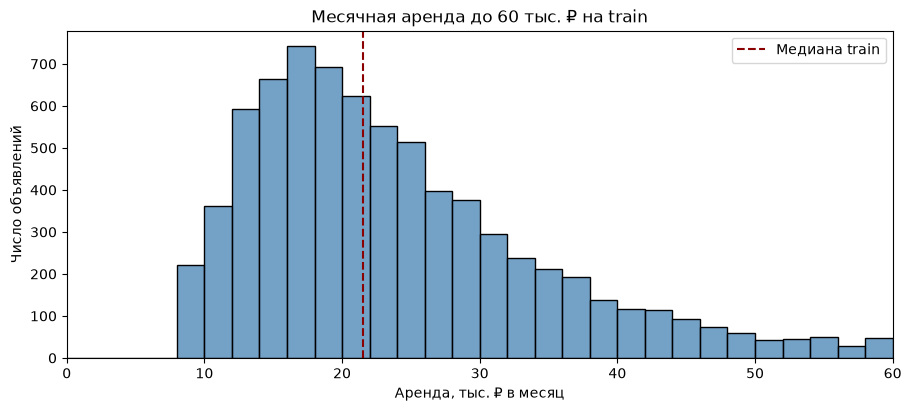

Дороже 60 тыс. ₽ – 298 из 7776 объявлений (3.8%).


In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

rent = audit[TARGET]
print(rent.describe().round().astype(int).to_string())

limit = 60_000
shown = rent[rent <= limit]
above_limit = (rent > limit).sum()

fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
sns.histplot(x=shown / 1000, bins=range(0, limit // 1000 + 1, 2), ax=ax, color="steelblue")
ax.axvline(rent.median() / 1000, color="darkred", linestyle="--", label="Медиана train")
ax.set(xlim=(0, limit / 1000), title="Месячная аренда до 60 тыс. ₽ на train",
       xlabel="Аренда, тыс. ₽ в месяц", ylabel="Число объявлений")
ax.legend()
plt.show()

print(f"Дороже 60 тыс. ₽ – {above_limit} из {len(rent)} объявлений ({above_limit / len(rent):.1%}).")


Медиана аренды – 21 500 ₽ в месяц. На train нижний квартиль цены – 16 000 ₽, верхний – 30 500 ₽. Дорогие квартиры образуют длинный правый хвост до 233 500 ₽ и поднимают среднее примерно до 25 739 ₽.

### Проверка выбросов и согласованности полей

По примеру практикума 2 вычисляем границы Тьюки для цены, общей площади и расстояния до метро. Границы находятся на расстоянии полутора межквартильных размахов от первого и третьего квартилей. Затем сверяем поля по смыслу.

In [10]:
features = audit[[TARGET, "total_area", "metro_distance_m"]]
q1 = features.quantile(0.25)
q3 = features.quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

pd.DataFrame({
    "Нижняя граница": lower.round(1),
    "Верхняя граница": upper.round(1),
    "Ниже границы": features.lt(lower).sum(),
    "Выше границы": features.gt(upper).sum(),
})

,Нижняя граница,Верхняя граница,Ниже границы,Выше границы
rent_rub,-5750.0,52250.0,0,456
total_area,-3.8,102.6,0,296
metro_distance_m,-5270.0,10650.0,0,120


In [11]:
above_building = audit["floor"] > audit["floors_total"]
living_above_total = audit["living_area"] > audit["total_area"]
rooms_above_total = audit["living_area"] + audit["kitchen_area"] > audit["total_area"]
print("Этаж квартиры выше этажности дома –", above_building.sum())
print("Жилая площадь больше общей –", living_above_total.sum())
print("Сумма жилой и кухонной площадей больше общей –", rooms_above_total.sum())

audit.nlargest(5, "total_area")[["rooms", "total_area", "living_area", "kitchen_area", TARGET]]

Этаж квартиры выше этажности дома – 32
Жилая площадь больше общей – 20
Сумма жилой и кухонной площадей больше общей – 139


,rooms,total_area,living_area,kitchen_area,rent_rub
4164,4,936.0,46.1,6.8,25000
2967,4,877.0,50.0,10.3,49000
9631,3,858.0,48.9,10.9,26000
1789,3,853.0,52.3,8.1,32000
8185,3,846.0,39.8,11.2,36500


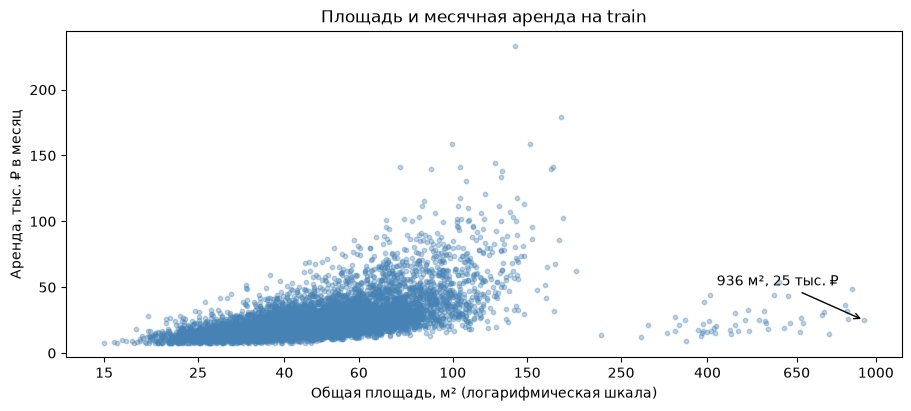

In [12]:
fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
ax.scatter(audit["total_area"], rent / 1000, s=10, alpha=0.35, color="steelblue")
ax.set_xscale("log")
ticks = [15, 25, 40, 60, 100, 150, 250, 400, 650, 1000]
ax.set_xticks(ticks, labels=ticks)
ax.minorticks_off()
ax.set(title="Площадь и месячная аренда на train",
       xlabel="Общая площадь, м² (логарифмическая шкала)", ylabel="Аренда, тыс. ₽ в месяц")

largest = audit["total_area"].idxmax()
area = audit.loc[largest, "total_area"]
price = rent.loc[largest] / 1000
ax.annotate(f"{area:g} м², {price:g} тыс. ₽", xy=(area, price),
            xytext=(-18, 25), textcoords="offset points", ha="right",
            arrowprops={"arrowstyle": "->"})
plt.show()

В основной группе объявлений с ростом площади растёт и разброс цен. При большой общей площади встречаются объявления с обычной ценой аренды. Например, у квартиры с общей площадью 936 м² указаны четыре комнаты, 46,1 м² жилой площади и цена 25 000 ₽. Возможна ошибка ввода общей площади. Для таких записей на этапе предобработки проверим согласованность полей. Проверим эту гипотезу по отношению общей площади к жилой на train.

У 32 записей этаж выше этажности дома, у 20 жилая площадь превышает общую. Эти признаки потребуют обработки. Верхнюю границу IQR для цены (52 250 ₽) превысили 456 объявлений. Высокая цена сама по себе возможна, поэтому сохраняем эти объявления для моделирования.

### Проверка общей площади

На train сравним общую и жилую площади. Если ошибка похожа на пропущенную десятичную запятую, деление общей площади на 10 вернёт отношение в обычный диапазон. Смотрим только объявления с положительной жилой площадью.

In [13]:
from modules.preprocessing import AREA_RATIO_LIMIT

ratio = audit["total_area"] / audit["living_area"].where(audit["living_area"] > 0)
suspect = ratio.gt(AREA_RATIO_LIMIT)
groups = pd.Series("До порога включительно", index=ratio.index)
groups.loc[suspect] = "Выше порога"
print("Объявлений без отношения площадей –", ratio.isna().sum())
print("Отношение после деления на 10 –",
      f"{ratio[suspect].min() / 10:.2f}–{ratio[suspect].max() / 10:.2f}")
ratio.groupby(groups).agg(["count", "min", "median", "max"]).round(2)

Объявлений без отношения площадей – 492
Отношение после деления на 10 – 1.30–2.20


,count,min,median,max
Выше порога,48,13.02,18.11,22.03
До порога включительно,7236,0.72,1.74,2.23


Отношение выше 4 у 48 из 7 776 объявлений train. У этой группы значения лежат между 13 и 22, а после деления общей площади на 10 – между 1,30 и 2,20. Разрыв между группами позволяет использовать порог 4. Исправляем общую площадь в пайплайне до проверки противоречий между площадями. Если жилая площадь пропущена, правило пропускает объявление.

### Проверка расстояния до метро

При аудите train заметили разрыв в расстояниях. Разделим объявления по порогу 15 км и сравним число строк, границы расстояния до метро и медиану расстояния до центра.

In [14]:
from modules.preprocessing import METRO_DISTANCE_LIMIT_M

metro = audit.loc[audit["metro_distance_m"].notna(), ["metro_distance_m", "distance_to_center_km"]]
metro_group = metro["metro_distance_m"].gt(METRO_DISTANCE_LIMIT_M).map({
    False: "До 15 км включительно",
    True: "Дальше 15 км",
})
metro.groupby(metro_group).agg(**{
    "Объявлений": ("metro_distance_m", "size"),
    "Мин. до метро, м": ("metro_distance_m", "min"),
    "Макс. до метро, м": ("metro_distance_m", "max"),
    "Медиана до центра, км": ("distance_to_center_km", "median"),
})

,Объявлений,"Мин. до метро, м","Макс. до метро, м","Медиана до центра, км"
metro_distance_m,,,,
Дальше 15 км,120,20050,45000,7.05
До 15 км включительно,7656,80,9000,7.10


В дальней группе 120 из 7 776 объявлений train. Между 9 000 и 20 050 м есть разрыв, а медианы расстояния до центра близки (7,10 и 7,05 км). Это повод проверить гипотезу об ошибке ×10. Если разделить значения выше 15 км на 10, они попадут в диапазон от 2 005 до 4 500 м. Проверим эффект на кросс-валидации в ноутбуке моделирования. В выбранном варианте пайплайна применяем эту поправку до логарифмирования расстояния.

## Пайплайн предобработки

По примеру практикума 5 собираем преобразования в один `Pipeline`. На вход подаём сырые характеристики объявления. Цену храним отдельно в рублях. Идентификатор `listing_id` исключаем из признаков: он нужен для поиска объявления.

Правила для нашего варианта вынесены в `modules/preprocessing.py`.

- Для районов убираем лишние пробелы, приводим текст к нижнему регистру и объединяем однозначные варианты названий. Например, «Ж/д» и «Железнодорожный р-н» получают одно значение. Неоднозначные названия оставляем отдельными категориями.
- Для студии записываем 0 отдельных комнат, добавляем признак студии и ставим 0 для отсутствующей площади отдельной кухни. Из года публикации и года постройки получаем возраст дома на момент объявления.
- Если этаж выше этажности дома или одна из площадей квартиры больше общей, сомнительное значение заменяем пропуском. Когда сумма жилой площади и кухни превышает общую, отмечаем противоречие отдельным признаком. По одной сумме нельзя определить, какое поле ошибочно.
- У общей площади и расстояния до метро длинный правый хвост. Используем `log1p`, чтобы уменьшить влияние крайних значений на масштаб признака. Это сохраняет порядок значений и допускает нулевое расстояние. Все объявления и исходные цены сохраняем.

In [15]:
import joblib
import numpy as np
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

from modules.preprocessing import CATEGORIES, prepare_features

X_train = train_df.drop(columns=TARGET)
X_validation = validation_df.drop(columns=TARGET)
y_train = pd.to_numeric(train_df[TARGET])
y_validation = pd.to_numeric(validation_df[TARGET])

Числовые пропуски заполняем медианой train, устойчивой к крайним значениям. Затем стандартизируем признаки: расстояния для kNN и штраф Ridge зависят от масштаба. Для категорий выделяем отдельное значение «не указано» и применяем one-hot кодирование. Так пропуск ремонта остаётся отличимым от категории «без ремонта». Если в новом объявлении встретится неизвестная категория, кодировщик сможет обработать строку.

In [16]:
numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
category_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="не указано")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

columns = ColumnTransformer([
    ("num", numeric_pipe, make_column_selector(dtype_include=np.number)),
    ("cat", category_pipe, CATEGORIES),
], verbose_feature_names_out=False).set_output(transform="pandas")

preprocessor = Pipeline([
    ("features", FunctionTransformer(prepare_features, kw_args={"correct_total_area": True, "correct_metro_distance": True})),
    ("columns", columns),
])

train_features = preprocessor.fit_transform(X_train)
validation_features = preprocessor.transform(X_validation)

assert train_features.index.equals(y_train.index)
assert validation_features.index.equals(y_validation.index)
assert train_features.columns.equals(validation_features.columns)
assert np.isfinite(train_features.to_numpy()).all()
assert np.isfinite(validation_features.to_numpy()).all()

print("Размер train –", train_features.shape)
print("Размер validation –", validation_features.shape)
train_features.iloc[:3, :8]

Размер train – (7776, 54)
Размер validation – (1944, 54)


,floors_total,floor,living_area,kitchen_area,ceiling_height,balcony,distance_to_center_km,description_length
3681,0.908034,-0.447983,-0.396856,0.276429,-1.211898,0.274893,-0.979472,-0.248857
5884,0.010001,0.442828,-0.198840,1.612681,-0.265181,0.274893,-0.526140,1.494369
9055,-1.067638,-0.670686,-1.337431,-2.024895,-1.401242,0.274893,-0.667806,-0.292275


### Сохранение результатов

В каждом CSV одна строка соответствует одному объявлению. Последний столбец – исходная цена `rent_rub` в рублях. В ноутбуке моделирования её нужно отделить от признаков. Обученный пайплайн сохраняем в формате joblib, чтобы затем объединить его с выбранной моделью.

Сохраняем также исходные строки train и validation в порядке подготовленных выборок. Сырой train нужен для повторного обучения предобработки внутри каждого блока кросс-валидации. В ноутбуке моделирования по ним найдём объявления с крупными ошибками и проверим прогноз по сырым признакам.

In [17]:
processed_dir = PROJECT_ROOT / "data" / "processed"
models_dir = PROJECT_ROOT / "models"
processed_dir.mkdir(parents=True, exist_ok=True)
models_dir.mkdir(exist_ok=True)

train_features.assign(rent_rub=y_train).to_csv(processed_dir / "train.csv", index=False)
validation_features.assign(rent_rub=y_validation).to_csv(processed_dir / "validation.csv", index=False)
train_df.to_csv(PROJECT_ROOT / "data" / "interim" / "train_raw.csv", index=False)
validation_df.to_csv(PROJECT_ROOT / "data" / "interim" / "validation_raw.csv", index=False)

pipeline_path = models_dir / "preprocessor.joblib"
joblib.dump(preprocessor, pipeline_path)

restored = joblib.load(pipeline_path)
pd.testing.assert_frame_equal(restored.transform(X_validation), validation_features)
print("Сохранены train.csv, validation.csv, train_raw.csv, validation_raw.csv и preprocessor.joblib.")
print("После загрузки пайплайн воспроизводит все значения validation.")

Сохранены train.csv, validation.csv, train_raw.csv, validation_raw.csv и preprocessor.joblib.
После загрузки пайплайн воспроизводит все значения validation.
